# 04 — Final Figures

Regenerates every paper figure/map via `src/viz.py` (read-only, no computation of its own —
see `CLAUDE.md`) and displays each with its caption and headline numbers, pulled fresh from
`outputs/tables/` rather than typed from memory. This is the last stop before the figures go
into the paper.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

import viz

paths = viz.main()
print(f"Regenerated {len(paths)} figures/maps:")
for p in paths:
    print(" -", p.relative_to(ROOT))

2026-07-04 20:20:32,842 | INFO    | colombo-uhi | Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\figures\correlation_heatmap.png


2026-07-04 20:20:32,844 | INFO    | colombo-uhi | Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\figures\lst_by_landcover_boxplot.png


2026-07-04 20:20:32,844 | INFO    | colombo-uhi | Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\figures\hei_distribution_histogram.png


2026-07-04 20:20:32,845 | INFO    | colombo-uhi | Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\maps\lst_map.png


2026-07-04 20:20:32,845 | INFO    | colombo-uhi | Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\maps\ndvi_map.png


2026-07-04 20:20:32,845 | INFO    | colombo-uhi | Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\maps\hotspots_map.png


2026-07-04 20:20:32,846 | INFO    | colombo-uhi | Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\maps\hei_map.png


Regenerated 7 figures/maps:
 - outputs\figures\correlation_heatmap.png
 - outputs\figures\lst_by_landcover_boxplot.png
 - outputs\figures\hei_distribution_histogram.png
 - outputs\maps\lst_map.png
 - outputs\maps\ndvi_map.png
 - outputs\maps\hotspots_map.png
 - outputs\maps\hei_map.png


## Figure 1 — Correlation matrix (land cells)

            lst   ndvi   ndbi  built_up
lst       1.000 -0.486  0.724     0.356
ndvi     -0.486  1.000 -0.784    -0.014
ndbi      0.724 -0.784  1.000     0.378
built_up  0.356 -0.014  0.378     1.000


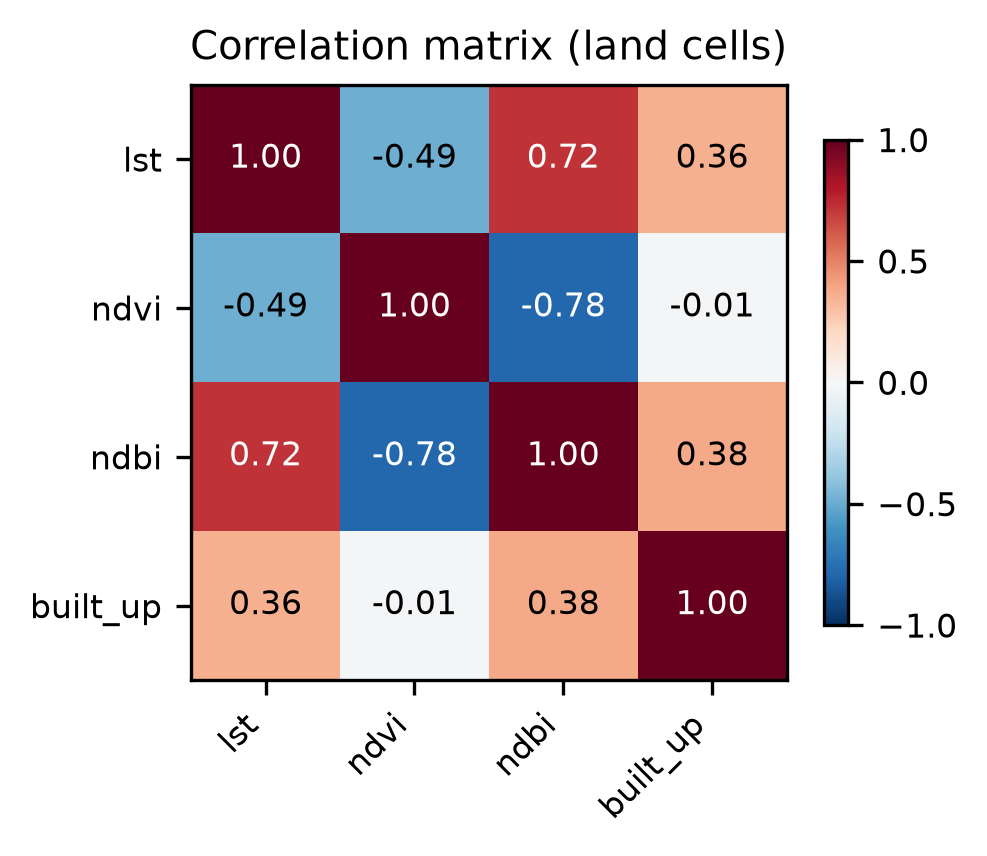

In [2]:
corr = pd.read_csv(ROOT / "outputs" / "tables" / "correlation_matrix.csv", index_col=0)
print(corr.round(3))
display(Image(filename=str(ROOT / "outputs" / "figures" / "correlation_heatmap.png")))

**Caption**: Pearson correlations among LST, NDVI, NDBI, and GHSL built-up surface, land
cells only (n=5,801). LST-NDBI strongly positive, LST-NDVI moderately negative, both derived
from the same 2024 Landsat composite; LST-built_up weaker (r≈0.36) since GHSL is a
different-year, different-provenance product.

## Figure 2 — LST by land cover

 lulc_class  count  mean  std   min   q25  median   q75   max
       10.0    533 38.65 2.33 31.66 37.68   39.04 40.19 44.16
       30.0    135 39.25 2.47 32.93 37.59   39.97 41.02 44.36
       40.0      9 36.65 2.25 32.87 34.75   37.56 38.21 39.64
       50.0   4703 41.38 1.56 33.71 40.51   41.36 42.36 47.34
       60.0    394 41.51 2.07 34.48 40.83   42.07 42.95 44.21
       90.0      3 34.81 1.95 33.22 33.72   34.22 35.61 36.99


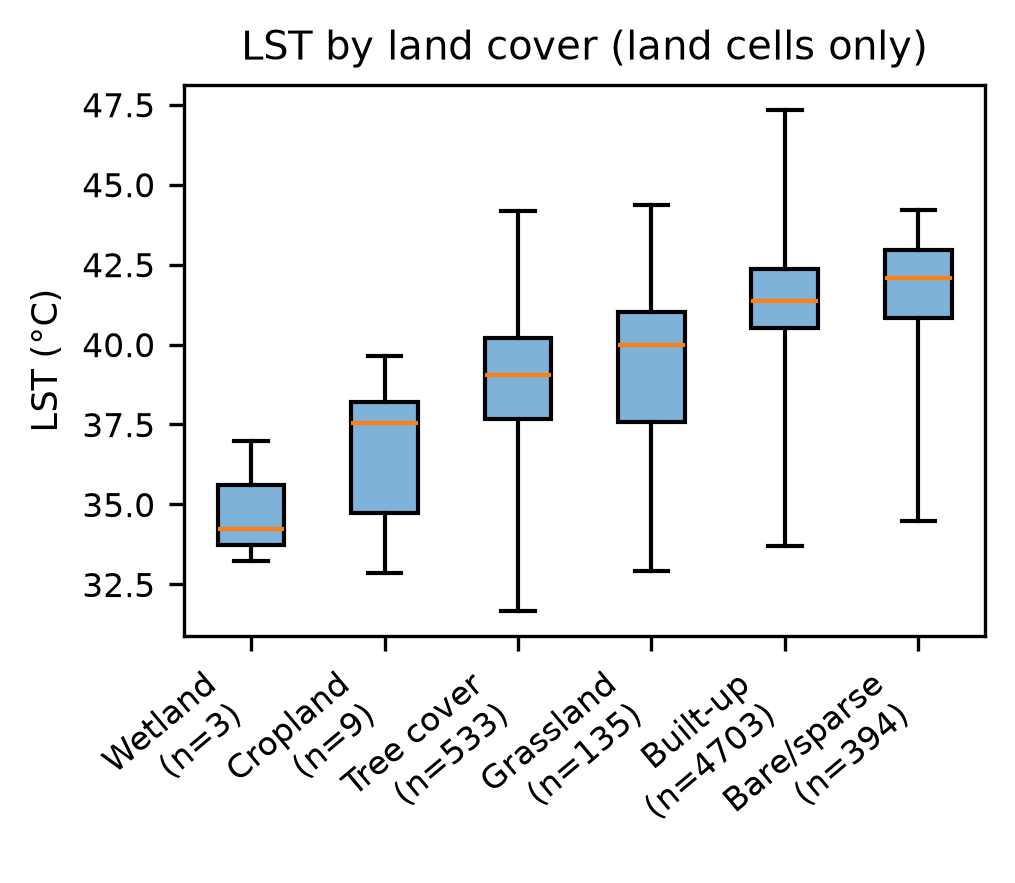

In [3]:
landcover = pd.read_csv(ROOT / "outputs" / "tables" / "lst_by_landcover.csv")
print(landcover.round(2).to_string(index=False))
display(Image(filename=str(ROOT / "outputs" / "figures" / "lst_by_landcover_boxplot.png")))

**Caption**: LST distribution by WorldCover class, land cells only. Built-up and bare/sparse
classes run hottest (~41.4-41.5°C median); wetland coolest (34.8°C) but n=3, flagged as
unreliable in the axis label rather than hidden.

## Figure 3 — HEI distribution

n valid = 5391
class-boundary cut points:
0.2    0.407
0.4    0.424
0.6    0.437
0.8    0.481


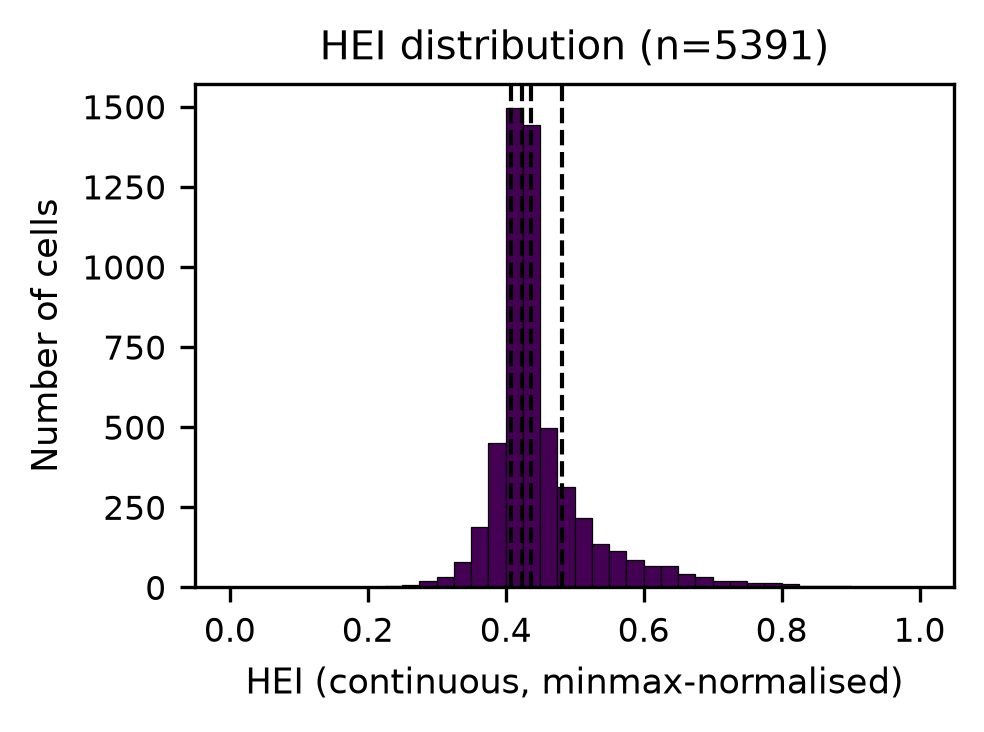

In [4]:
hei = pd.read_csv(ROOT / "outputs" / "tables" / "hei_by_cell.csv")
valid_hei = hei["hei"].dropna()
cuts = valid_hei.quantile([0.2, 0.4, 0.6, 0.8])
print(f"n valid = {len(valid_hei)}")
print("class-boundary cut points:")
print(cuts.round(3).to_string())
display(Image(filename=str(ROOT / "outputs" / "figures" / "hei_distribution_histogram.png")))

**Caption**: Continuous HEI distribution (n=5,391 valid cells) with the 4 quantile cut
points (dashed) that define the 5-class map in Figure 6. Sharply right-skewed — see
`03_hvi_experiments.ipynb` for why quantile (not equal-interval) classification is the right
choice given this shape.

## Figure 4 — Land Surface Temperature map

land-only LST range: 31.66 - 47.34 degC (mean 41.08)


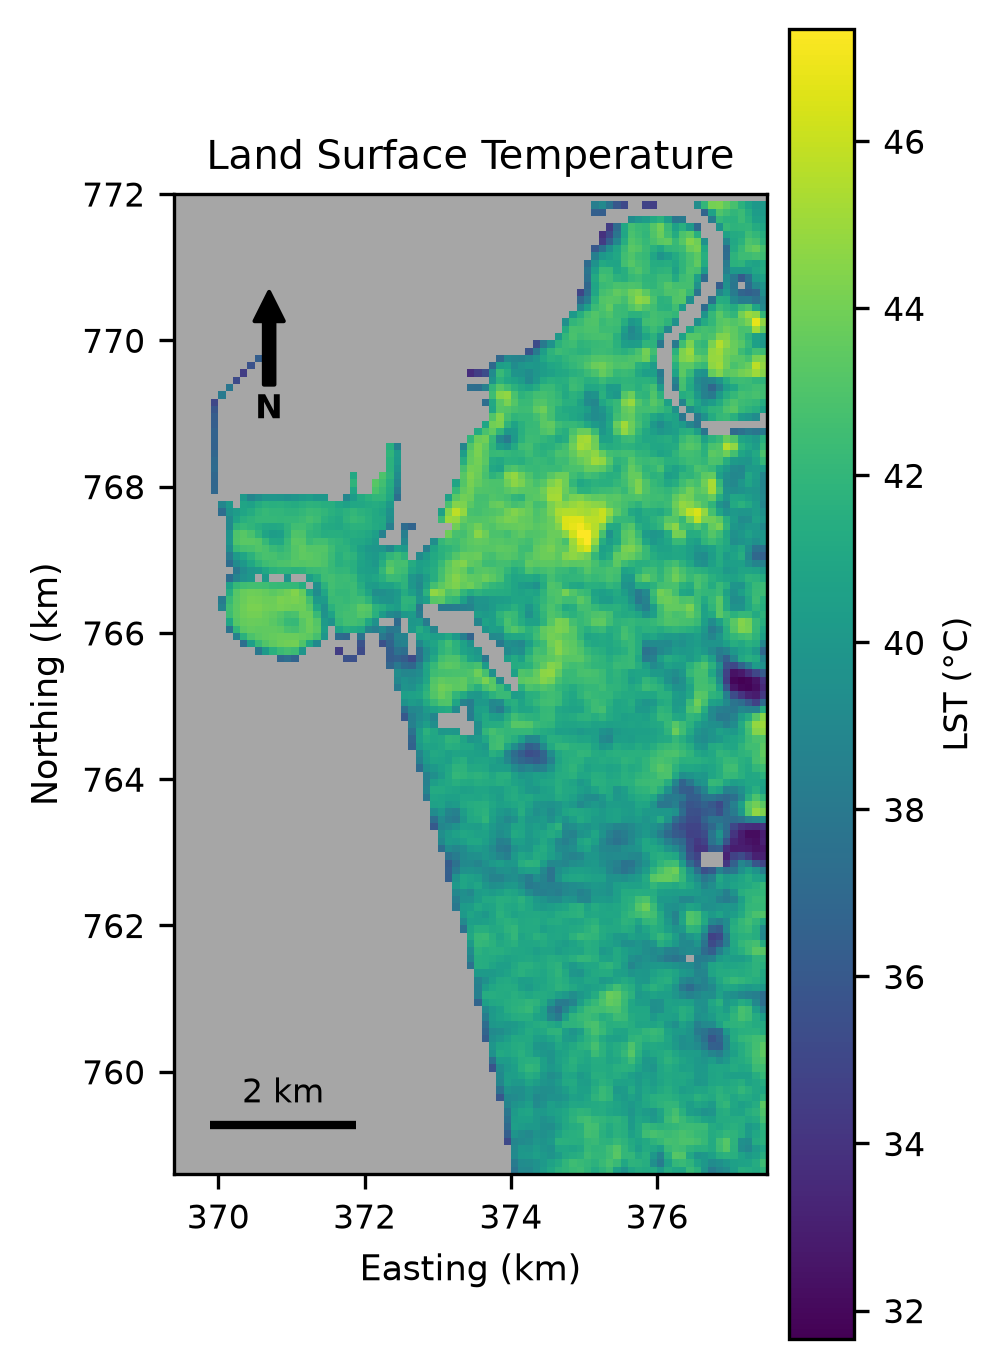

In [5]:
land_lst = hei.loc[hei["land_mask"], "lst"].dropna()
print(f"land-only LST range: {land_lst.min():.2f} - {land_lst.max():.2f} degC (mean {land_lst.mean():.2f})")
display(Image(filename=str(ROOT / "outputs" / "maps" / "lst_map.png")))

**Caption**: Land Surface Temperature over the study bbox, EPSG:32644. Water masked grey
(never entered into any statistic). Viridis (sequential, colour-blind-safe).

## Figure 5 — NDVI map

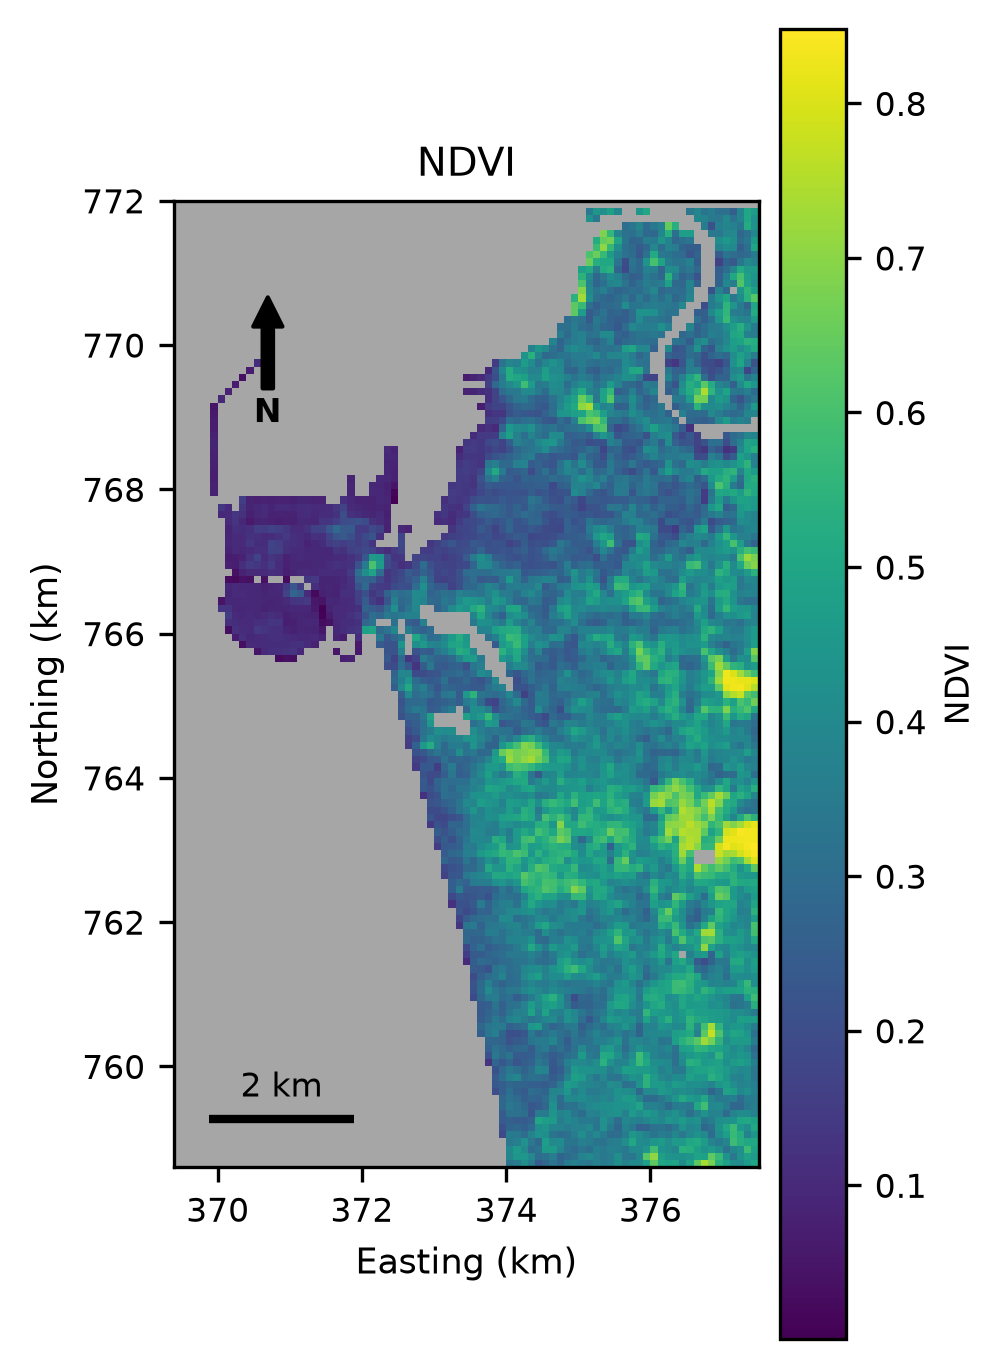

In [6]:
display(Image(filename=str(ROOT / "outputs" / "maps" / "ndvi_map.png")))

**Caption**: NDVI over the study bbox, same extent/styling as Figure 4. Note the
near-zero-NDVI western reclaimed peninsula (Colombo Port City) — see `CLAUDE.md` /
`reports/methodology_notes.md` for its role as a dataset-year-mismatch example.

## Figure 6 — Getis-Ord Gi* hot/cold spots

FDR-corrected Gi* counts: {'ns': 4470, 'hot': 873, 'cold': 434}


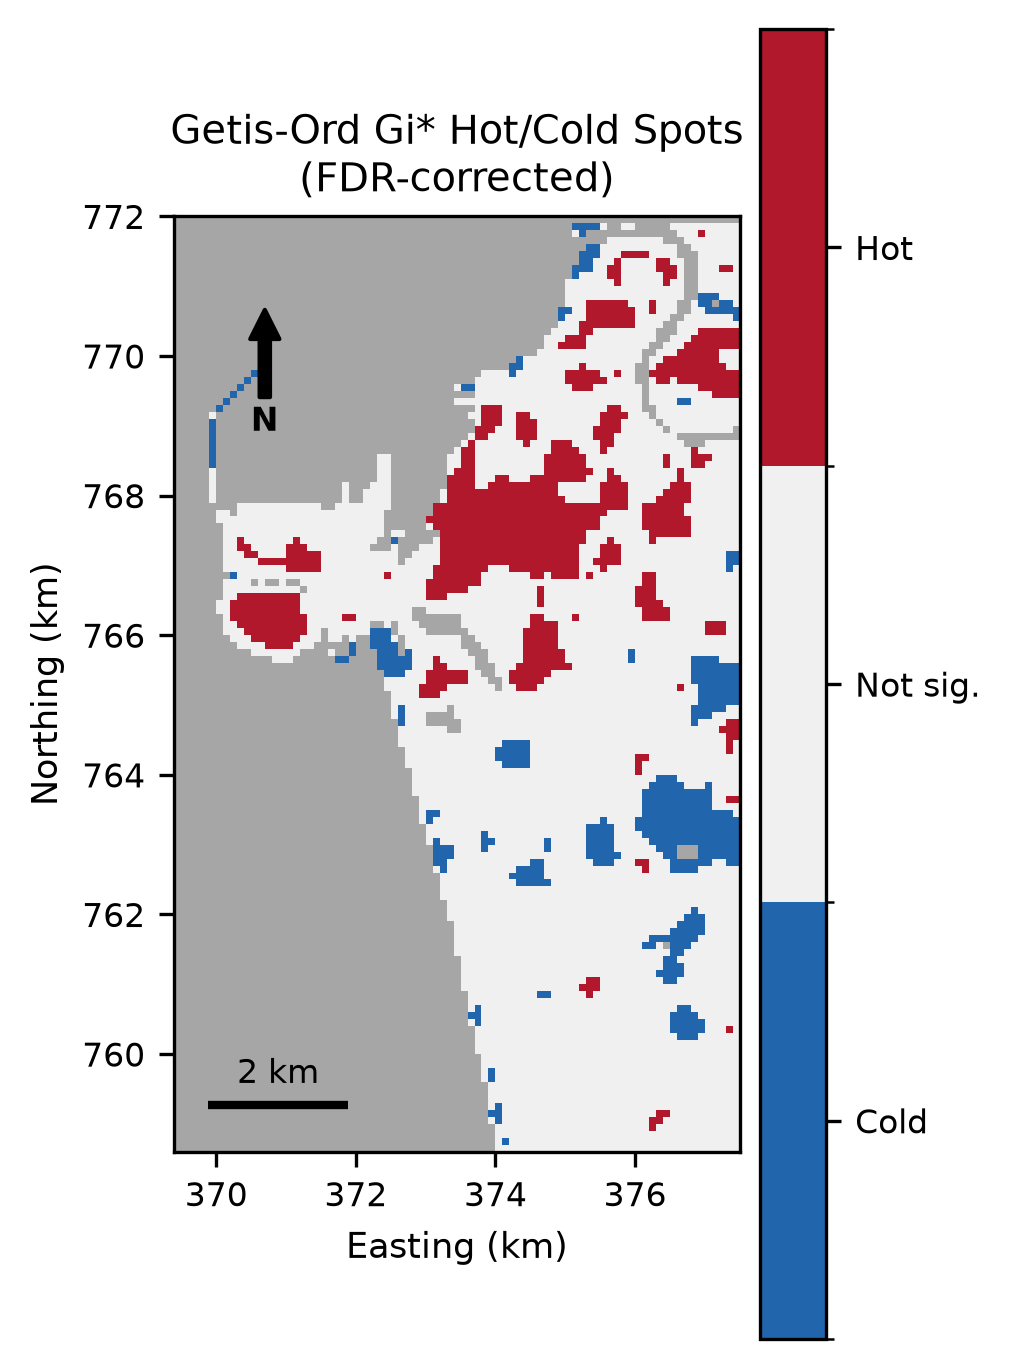

In [7]:
hotspots = pd.read_csv(ROOT / "outputs" / "tables" / "hotspots.csv")
counts = hotspots["label"].value_counts()
print("FDR-corrected Gi* counts:", counts.to_dict())
display(Image(filename=str(ROOT / "outputs" / "maps" / "hotspots_map.png")))

**Caption**: Getis-Ord Gi* (star=True, FDR-corrected at alpha=0.05), computed over the
land+valid-LST subset (5,777 cells). Global Moran's I = 0.7978 (p=0.001) confirms the
underlying spatial clustering is real before looking at local hot/cold spots.

## Figure 7 — Heat Exposure Index (5-class) map

HEI class counts (quantile, ~equal by construction):


hei_class
1.0    1079
2.0    1078
3.0    1078
4.0    1078
5.0    1078


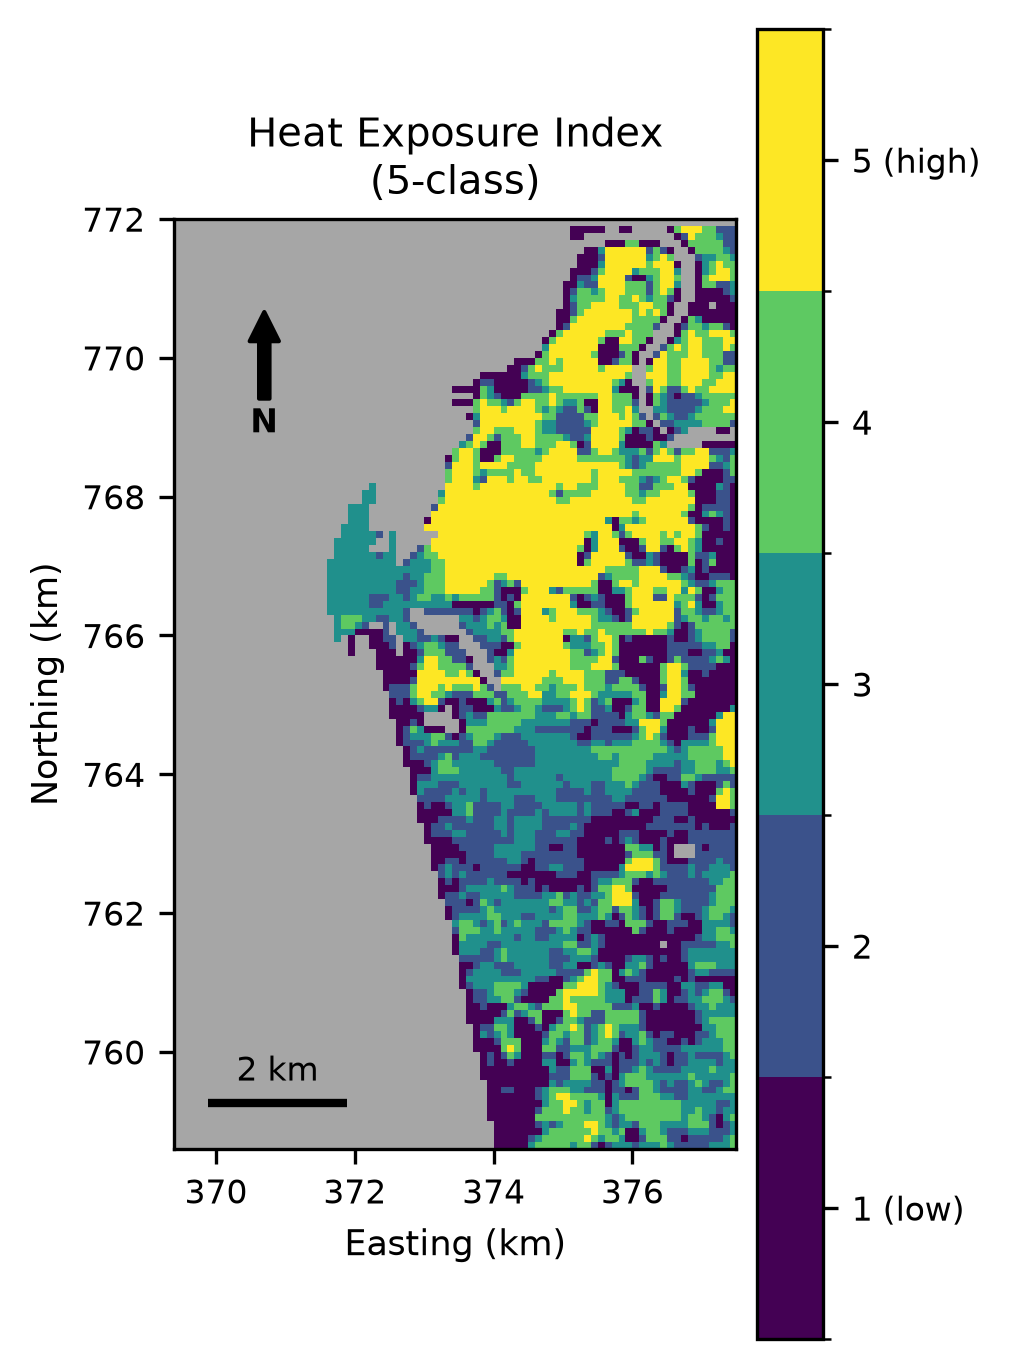

In [8]:
class_counts = hei["hei_class"].value_counts().sort_index()
print("HEI class counts (quantile, ~equal by construction):")
print(class_counts.to_string())
display(Image(filename=str(ROOT / "outputs" / "maps" / "hei_map.png")))

**Caption**: Heat Exposure Index, 5-class quantile map, `HEI = minmax(lst_z * pop_density *
(1-ndvi))`. Called Heat Exposure/Risk Index throughout, never "Heat Vulnerability Index" — no
socioeconomic/adaptive-capacity data. See `03_hvi_experiments.ipynb` for the sensitivity
analysis behind this map's design choices.